# Gráfico 3: top 15 mercados por revalorización de la vivienda (nominal), es decir, no tiene en ceunta la subida de la inflación

Este gráfico muestra los 15 países en donde más ha crecido de media al año el precio de la vivienda entre 2015 y 2024, con España al final con su puesto.

**Datos:** `limpio_vivienda.csv` (carpeta `data/Depurados`; 57 países, 2015-2024). Precios nominales, sin descontar inflación.

## 1 Librerías y funciones propias (src/utils/archivos.py)

In [1]:
import sys
sys.path.append("..")
from utils.archivos import cargar_dataset, guardar_grafico

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2 Cargo los datos

In [2]:
vivienda = cargar_dataset("limpio_vivienda.csv", carpeta="Depurados")
vivienda.shape

(570, 4)

## 3 Calculo el ranking (con España al final)

In [3]:
ranking = vivienda.groupby("pais")["crec._precio_(%)"].mean().round(1)
ranking = ranking.sort_values(ascending=False).reset_index()
ranking["puesto"] = ranking.index + 1
ranking["etiqueta"] = "#" + ranking["puesto"].astype(str) + " " + ranking["pais"] + " (" + ranking["crec._precio_(%)"].astype(str) + " %)"
top15 = pd.concat([ranking.head(15), ranking[ranking["pais"] == "Spain"]])
top15

,pais,crec._precio_(%),puesto,etiqueta
0,Türkiye,41.0,1,#1 Türkiye (41.0 %)
1,Hungary,13.5,2,#2 Hungary (13.5 %)
2,Iceland,10.6,3,#3 Iceland (10.6 %)
3,Serbia,9.9,4,#4 Serbia (9.9 %)
4,Lithuania,9.4,5,#5 Lithuania (9.4 %)
5,Czechia,8.9,6,#6 Czechia (8.9 %)
6,Portugal,8.8,7,#7 Portugal (8.8 %)
7,Chile,8.7,8,#8 Chile (8.7 %)
8,Estonia,8.6,9,#9 Estonia (8.6 %)
9,Bulgaria,8.5,10,#10 Bulgaria (8.5 %)


## 4 Dibujo y guardo el gráfico

Guardado: c:\Users\Agus\Bootcamp\proyectos\4_PROYECTO_2 EDA\src\visualizaciones\03_top15_revalorizacion_nominal.png


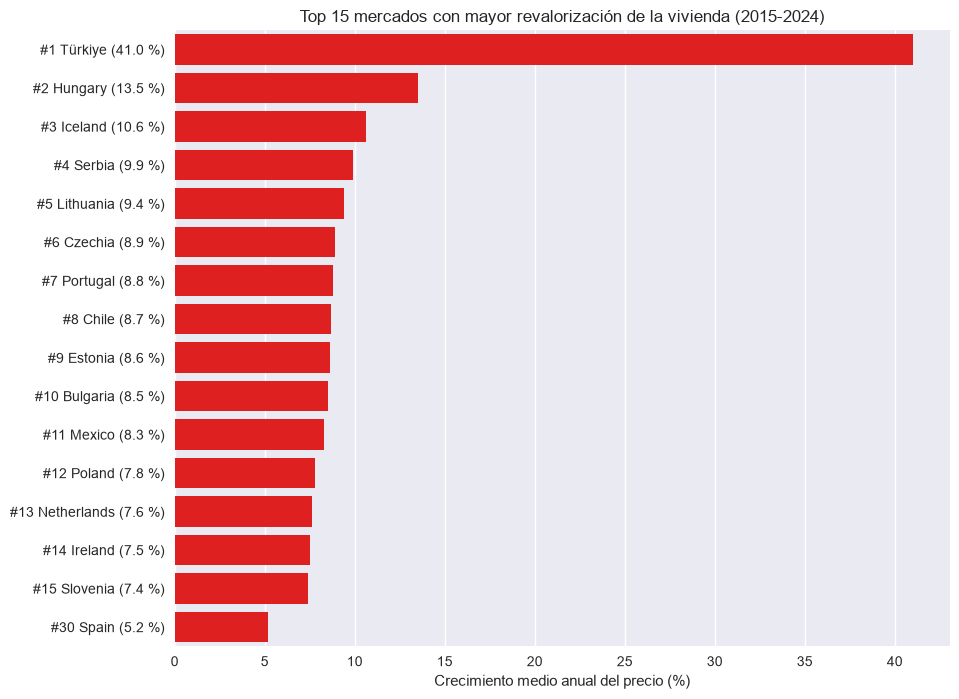

In [4]:
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(10, 8))

sns.barplot(data=top15, x="crec._precio_(%)", y="etiqueta", color="red")

plt.title("Top 15 mercados con mayor revalorización de la vivienda (2015-2024)")
plt.xlabel("Crecimiento medio anual del precio (%)")
plt.ylabel("")
guardar_grafico("03_top15_revalorizacion_nominal.png")
plt.show()